# Matplotlib – your first business charts

**Video 8.2** · ShopKart project

**Goal:** Draw the three charts every analyst needs – bar (compare categories), line (trend over time) and histogram (distribution) – with titles, labels, size, and save them as PNG files.

**How to open in Colab:** go to colab.research.google.com → File → Upload notebook → choose this file. Then click the folder icon on the left and drag these data files in: `shopkart_clean.csv`. Then run cells from top to bottom (Shift + Enter).

## Step 1 – Load the data
We use `shopkart_clean.csv`, the file we produced at the end of Module 6.

In [1]:
# Import the libraries we need
import os
import pandas as pd
import matplotlib.pyplot as plt

# Load the clean ShopKart data we created in Module 6
df = pd.read_csv("shopkart_clean.csv")

# A folder to save our chart images into
os.makedirs("images", exist_ok=True)

print(df.shape)
df.head(3)

(5000, 21)


,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,city,payment_mode,delivery_days,...,returned,product_name,category,cost_price,gender,age,membership,revenue,profit,order_month
0,O10001,2025-01-01,C0593,P048,6,362,0.20,Delhi,COD,4,...,N,Wings of Fire,Books,240,Female,26,Prime,1737.6,297.6,1
1,O10002,2025-01-01,C0367,P049,2,300,0.05,Chennai,Debit Card,4,...,N,Face Wash,Beauty,150,Male,35,Free,570.0,270.0,1
2,O10003,2025-01-01,C0707,P020,1,2258,0.05,Delhi,Debit Card,2,...,N,Saree,Fashion,1280,Male,41,Prime,2145.1,865.1,1


In [2]:
# Our course colours: one main colour, one highlight colour, one grey
MAIN = "#2a78d6"       # blue  - normal bars and lines
HIGHLIGHT = "#eb6834"  # orange - the one thing we want people to notice
GREY = "#b8b6ae"       # grey  - everything else

## Step 2 – Bar chart: revenue by category
A bar chart **compares categories**. First we make the small summary table with `groupby` (Module 6), then we plot it.

In [3]:
# Total revenue per category, biggest first, in lakh rupees
cat_rev = df.groupby("category")["revenue"].sum().sort_values(ascending=False) / 100000
cat_rev.round(1)

category
Electronics    73.3
Fashion        31.2
Home           26.6
Beauty          8.8
Books           7.2
Name: revenue, dtype: float64

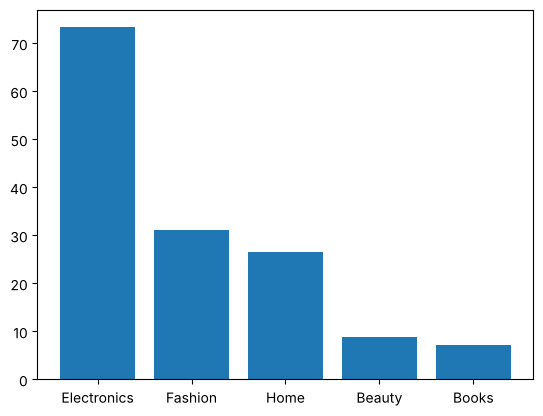

In [4]:
# The simplest bar chart: x = category names, height = revenue
plt.bar(cat_rev.index, cat_rev.values)
plt.show()

That works, but nobody knows what the numbers mean. A chart without a title and axis labels is **unfinished**. Let's add them.

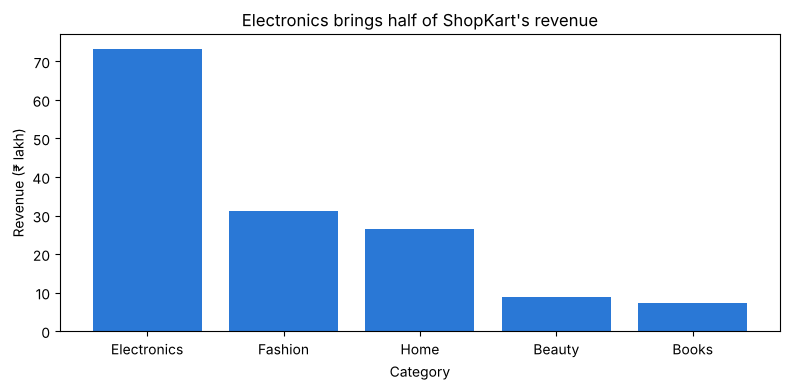

In [5]:
plt.figure(figsize=(8, 4))                   # width 8, height 4 (inches)
plt.bar(cat_rev.index, cat_rev.values, color=MAIN)
plt.title("Electronics brings half of ShopKart's revenue")   # a title that says the finding
plt.xlabel("Category")
plt.ylabel("Revenue (₹ lakh)")
plt.tight_layout()                            # stops labels being cut off
plt.savefig("images/M08_revenue_by_category.png", dpi=150)   # save BEFORE plt.show()
plt.show()

## Step 3 – Line chart: monthly revenue
A line chart shows a **trend over time**. `order_month` is the month number (1 = January).

In [6]:
monthly = df.groupby("order_month")["revenue"].sum() / 100000
monthly.round(1)

order_month
1     10.7
2      8.6
3     10.8
4      9.8
5      7.9
6      7.9
7      8.7
8     12.0
9     15.4
10    19.8
11    19.7
12    15.6
Name: revenue, dtype: float64

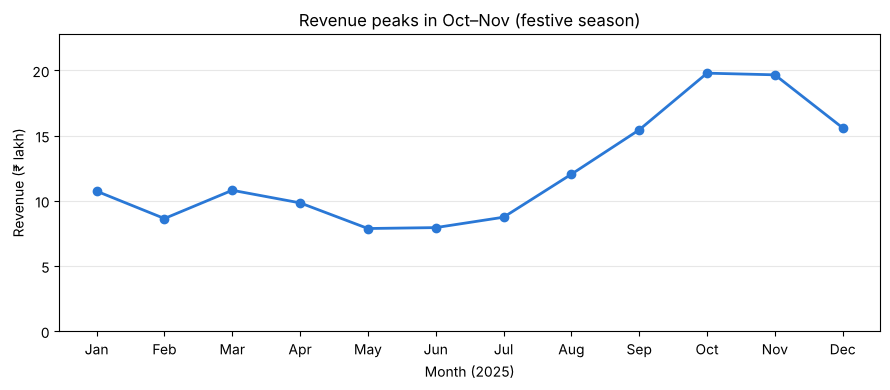

In [7]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(9, 4))
plt.plot(monthly.index, monthly.values, marker="o", color=MAIN, linewidth=2)
plt.xticks(monthly.index, month_names)        # show month names instead of 1..12
plt.ylim(0, monthly.max() * 1.15)             # start the y-axis at 0
plt.title("Revenue peaks in Oct–Nov (festive season)")
plt.xlabel("Month (2025)")
plt.ylabel("Revenue (₹ lakh)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("images/M08_monthly_revenue.png", dpi=150)
plt.show()

In [8]:
# Check the numbers behind the story
print("Best month :", month_names[monthly.idxmax() - 1], round(monthly.max(), 1), "lakh")
print("Worst month:", month_names[monthly.idxmin() - 1], round(monthly.min(), 1), "lakh")

Best month : Oct 19.8 lakh
Worst month: May 7.9 lakh


## Step 4 – Histogram: how big is a typical order?
A histogram shows a **distribution**: how many orders fall in each revenue range (bin). Most orders are small and a few are huge, so the full histogram is squashed on the left (right-skewed – remember Module 3).

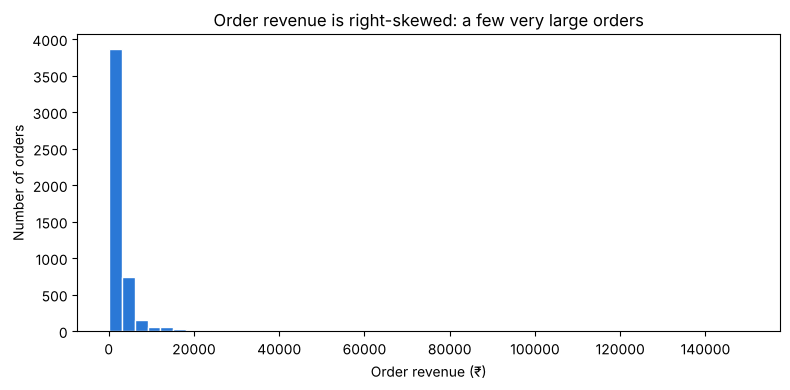

Median order: 1524.8  Mean order: 2940.93  Biggest order: 149990.0


In [9]:
plt.figure(figsize=(8, 4))
plt.hist(df["revenue"], bins=50, color=MAIN, edgecolor="white")
plt.title("Order revenue is right-skewed: a few very large orders")
plt.xlabel("Order revenue (₹)")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.show()

print("Median order:", df["revenue"].median(), " Mean order:", round(df["revenue"].mean(), 2),
      " Biggest order:", df["revenue"].max())

4773 of 5000 orders are ₹10,000 or less


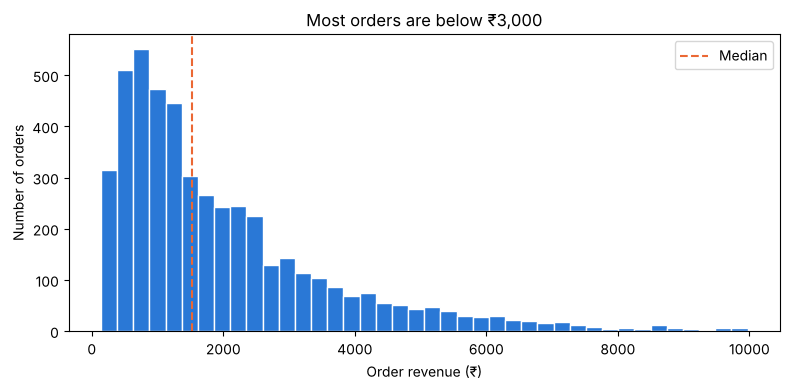

In [10]:
# Zoom in on orders up to ₹10,000 to see the shape of the "normal" orders
small = df[df["revenue"] <= 10000]
print(len(small), "of", len(df), "orders are ₹10,000 or less")

plt.figure(figsize=(8, 4))
plt.hist(small["revenue"], bins=40, color=MAIN, edgecolor="white")
plt.axvline(df["revenue"].median(), color=HIGHLIGHT, linestyle="--", label="Median")
plt.legend()
plt.title("Most orders are below ₹3,000")
plt.xlabel("Order revenue (₹)")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.savefig("images/M08_revenue_histogram.png", dpi=150)
plt.show()

## Step 5 – Two charts side by side (subplots)
`plt.subplots(1, 2)` gives you one figure with 2 boxes (axes). With axes we write `ax.set_title` instead of `plt.title`.

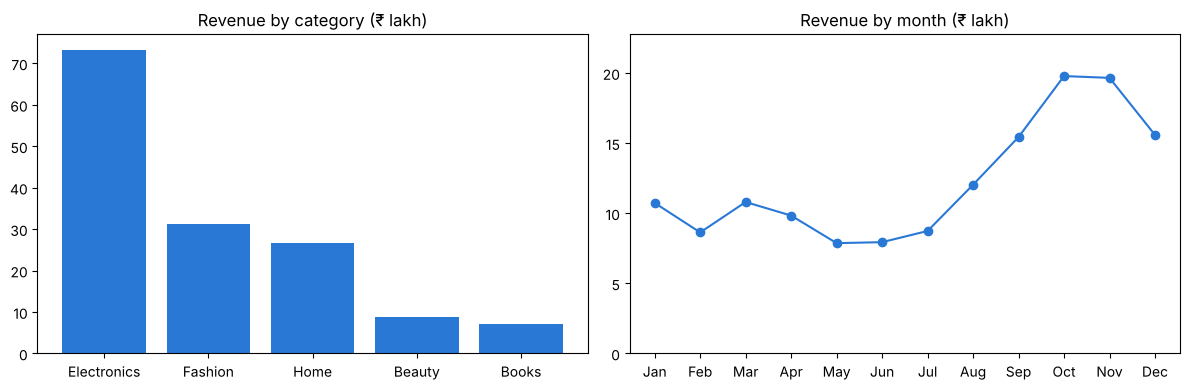

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(cat_rev.index, cat_rev.values, color=MAIN)
axes[0].set_title("Revenue by category (₹ lakh)")

axes[1].plot(monthly.index, monthly.values, marker="o", color=MAIN)
axes[1].set_xticks(monthly.index, month_names)
axes[1].set_ylim(0, monthly.max() * 1.15)
axes[1].set_title("Revenue by month (₹ lakh)")

plt.tight_layout()
plt.savefig("images/M08_two_charts.png", dpi=150)
plt.show()

In [12]:
# Which files did we save?
sorted(os.listdir("images"))

['M08_monthly_revenue.png',
 'M08_revenue_by_category.png',
 'M08_revenue_histogram.png',
 'M08_two_charts.png']

## Your turn (practice)
Make a **horizontal** bar chart (`plt.barh`) of total revenue by **city**, sorted, with a message title. Save it as `images/M08_revenue_by_city.png`.

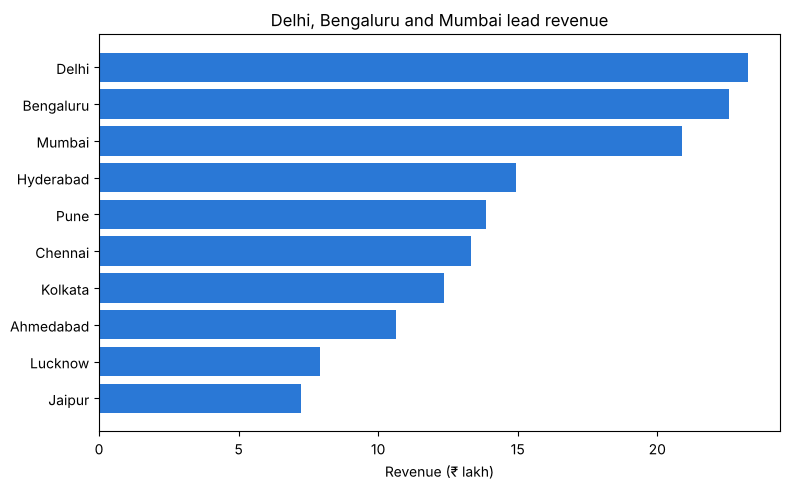

In [13]:
city_rev = df.groupby("city")["revenue"].sum().sort_values() / 100000
plt.figure(figsize=(8, 5))
plt.barh(city_rev.index, city_rev.values, color=MAIN)
plt.title("Delhi, Bengaluru and Mumbai lead revenue")
plt.xlabel("Revenue (₹ lakh)")
plt.tight_layout()
plt.savefig("images/M08_revenue_by_city.png", dpi=150)
plt.show()